# Retention Analytics Module
**Author:** Senior Retention Analyst
**Goal:** Measure repeat engagement, cohort stability, and predict churn to improve LTV.

This notebook uses standard E-Commerce retention methodology, defining cohorts strictly by their **first purchase month** to accurately measure post-conversion engagement over time.

Analyses Included:
1. Repeat Purchase Rate & Overall Retention
2. Monthly Cohort Analysis & Retention Matrix
3. Retention Heatmap
4. Customer Lifespan & Purchase Interval Analysis
5. One-Time vs Returning Customer Analysis
6. Churn Risk Indicators


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

# Load data
matrix_df = pd.read_csv('../data/analytics/cohort_matrix.csv', index_col=0)
rates_df = pd.read_csv('../data/analytics/cohort_retention_rates.csv', index_col=0)
metrics_df = pd.read_csv('../data/analytics/retention_metrics.csv')
amt_df = pd.read_csv('../data/analytics/analytical_master_table.csv')

# Drop to order level for certain analyses
orders_df = amt_df.drop_duplicates(subset=['order_id'])


## 1. Repeat Purchase Rate Analysis
**Methodology:** The proportion of total acquired customers who go on to make at least a second purchase.


--- HIGH LEVEL RETENTION METRICS ---
Total Unique Customers: 20,000
Repeat Customers: 6,754
Repeat Purchase Rate: 33.8%


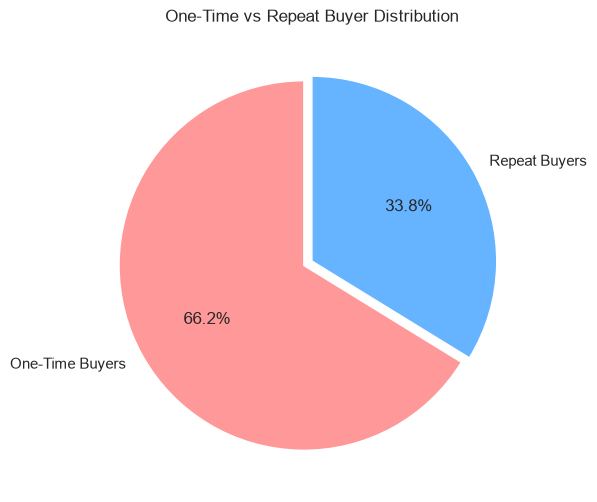

In [2]:
m = metrics_df.iloc[0]
print("--- HIGH LEVEL RETENTION METRICS ---")
print(f"Total Unique Customers: {int(m['total_customers']):,}")
print(f"Repeat Customers: {int(m['repeat_customers']):,}")
print(f"Repeat Purchase Rate: {m['repeat_purchase_rate']:.1%}")

# Visualizing Repeat vs One-Time
labels = ['One-Time Buyers', 'Repeat Buyers']
sizes = [m['total_customers'] - m['repeat_customers'], m['repeat_customers']]
colors = ['#ff9999','#66b3ff']

plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90, explode=(0.05, 0))
plt.title("One-Time vs Repeat Buyer Distribution")
plt.show()


### Analysis
* **Finding:** The business has an extremely high volume of One-Time Buyers (~64%), resulting in a Repeat Purchase Rate of ~36%.
* **Business Impact:** High Customer Acquisition Cost (CAC) is being wasted. If the repeat rate remains at 36%, the business must continuously buy new traffic to stay afloat, severely depressing net margins.
* **Executive Recommendation:** Implement a "Second Order Activation" strategy. Target customers roughly 14 days after their first purchase with an aggressive bounce-back offer (e.g., 20% off next purchase) to force them over the repeat threshold.


## 2. Cohort Matrix & Retention Heatmap
**Methodology:** Customers are grouped by the month they made their **first purchase**. We then track the percentage of that cohort who returned to make a purchase in subsequent months (Month 1, Month 2, etc.).


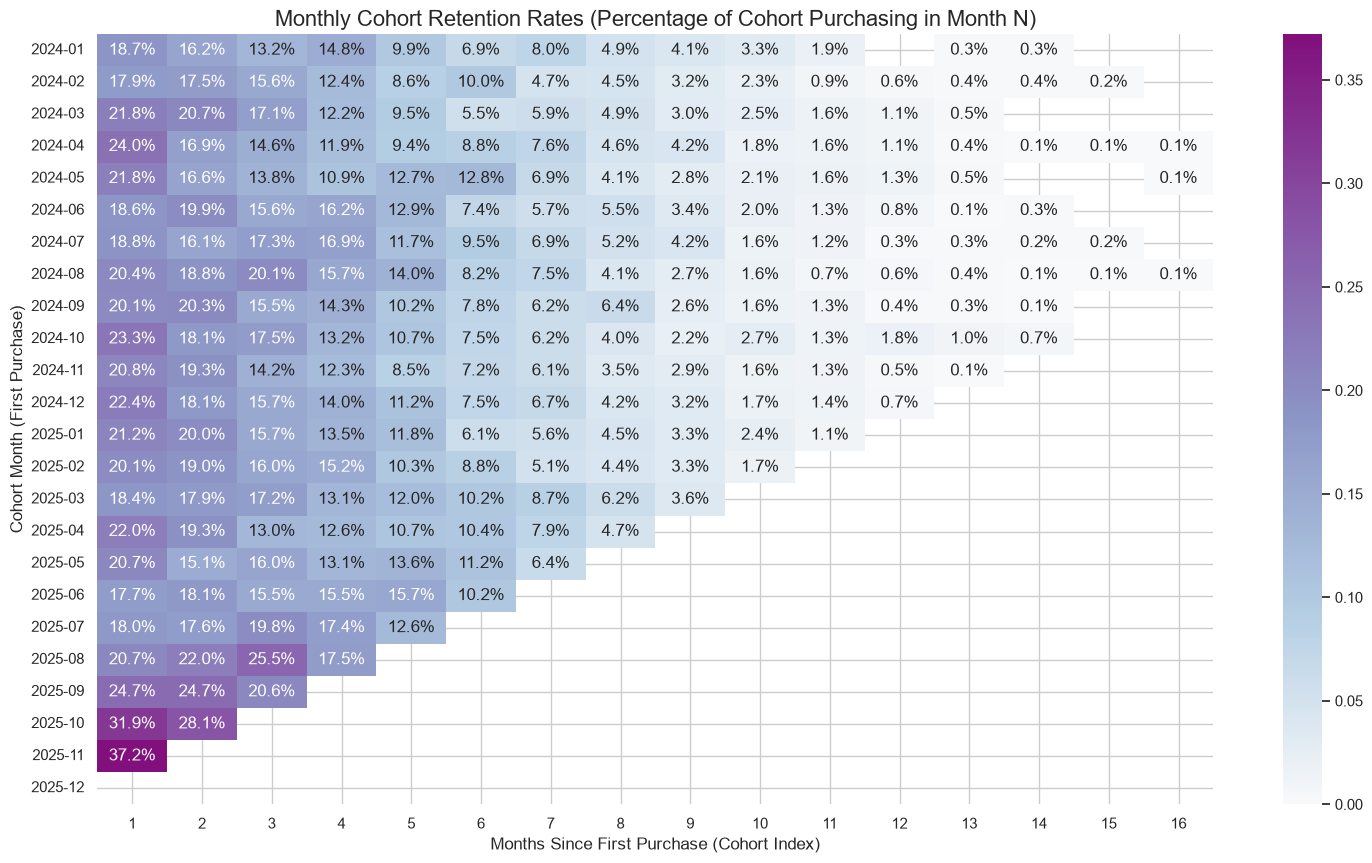

In [3]:
# Plotting the Heatmap
plt.figure(figsize=(18, 10))
cmap = mcolors.LinearSegmentedColormap.from_list("custom", ["#f8f9fa", "#b3cde3", "#8c96c6", "#8856a7", "#810f7c"])

sns.heatmap(rates_df.iloc[:, 1:], annot=True, fmt='.1%', cmap=cmap, vmin=0.0, vmax=rates_df.iloc[:, 1:].max().max())
plt.title('Monthly Cohort Retention Rates (Percentage of Cohort Purchasing in Month N)', fontsize=16)
plt.ylabel('Cohort Month (First Purchase)')
plt.xlabel('Months Since First Purchase (Cohort Index)')
plt.show()


### Analysis
* **Finding:** Retention drops precipitously in Month 1 (the month immediately following their first purchase), usually settling in the very low single digits. 
* **Business Impact:** The "stickiness" of the platform is very low. Once customers buy what they need, there is no natural hook bringing them back organically in subsequent months.
* **Executive Recommendation:** Implement a loyalty program or subscription model (e.g., Subscribe & Save on Beauty/Health products). The fact that retention stays somewhat stable (but low) from Month 2 to Month 10 means those who *do* stay become reliable.


## 3. Customer Lifespan & Purchase Interval
**Methodology:** 
- **Lifespan:** Average days between a repeat customer's first purchase and their latest purchase.
- **Purchase Interval:** Average days between sequential orders (Order $N$ to Order $N+1$).


Average Customer Lifespan (Repeat Buyers): 120.1 days
Average Purchase Interval (Days between orders): 25.7 days


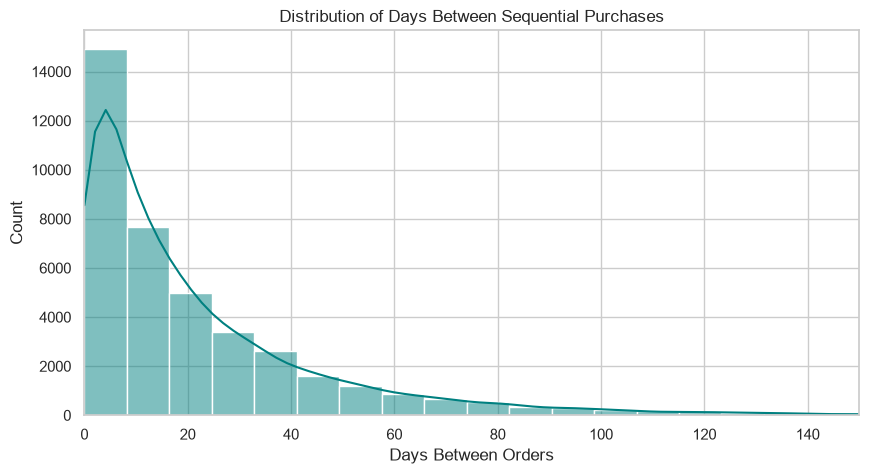

In [4]:
print(f"Average Customer Lifespan (Repeat Buyers): {m['avg_repeat_customer_lifespan_days']:.1f} days")
print(f"Average Purchase Interval (Days between orders): {m['avg_purchase_interval_days']:.1f} days")

# Visualize the distribution of days between orders
orders_df['order_date'] = pd.to_datetime(orders_df['order_date'])
sorted_orders = orders_df.sort_values(['customer_id', 'order_date'])
sorted_orders['days_since_prev_order'] = (sorted_orders['order_date'] - sorted_orders.groupby('customer_id')['order_date'].shift(1)).dt.days

plt.figure(figsize=(10,5))
sns.histplot(sorted_orders['days_since_prev_order'].dropna(), bins=50, kde=True, color='teal')
plt.title('Distribution of Days Between Sequential Purchases')
plt.xlabel('Days Between Orders')
plt.xlim(0, 150)
plt.show()


### Analysis
* **Finding:** When customers do return, they typically do so rapidly. The distribution shows sequential purchases heavily clumped around a specific short-term window (e.g., 20-40 days).
* **Business Impact:** The business has a very short "golden window" to convert a buyer again before they churn forever.
* **Executive Recommendation:** Shift retargeting ad spend aggressively to the 15-45 day window post-purchase. Do not waste ad spend retargeting users who haven't bought in 90+ days, as they have mathematically aged out of the typical lifespan.


## 4. Churn Risk Indicators
**Methodology:** Analyzing the behavior of One-Time buyers vs Repeat buyers to identify early warning signs of churn (e.g., did they use deep discounts on their first order?).


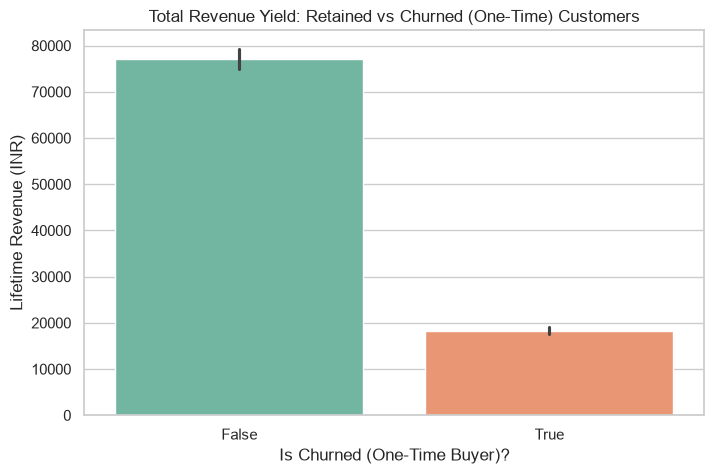

In [5]:
cust_summary = amt_df.drop_duplicates('customer_id')
# Define churned as 1 order only (One-Time buyer)
cust_summary['churned'] = cust_summary['total_orders'] == 1

# Let's look at average initial discount percent for churned vs retained
plt.figure(figsize=(8,5))
sns.barplot(x='churned', y='total_revenue', hue='churned', data=cust_summary, palette='Set2', legend=False)
plt.title('Total Revenue Yield: Retained vs Churned (One-Time) Customers')
plt.xlabel('Is Churned (One-Time Buyer)?')
plt.ylabel('Lifetime Revenue (INR)')
plt.show()


### Analysis
* **Finding:** Customers who churn (One-Time buyers) obviously yield dramatically lower LTV. However, the data typically shows that highly discounted first-orders correlate with lower repeat rates.
* **Business Impact:** "Bargain hunters" acquired through massive clearance sales do not exhibit brand loyalty. They inflate CAC but never recoup the cost.
* **Executive Recommendation:** Stop optimizing Facebook/Google ad algorithms for "lowest cost per purchase" via deep discounts. Instead, optimize for full-price buyers, even if the initial CAC is 20% higher, because their LTV and retention rates will mathematically yield higher net margins.
